# Redução de dimensionalidade e PCA

Em problemas de Machine Learning, cada amostra pode possuir muitas características (*features*). Algumas podem conter informações redundantes ou estar fortemente correlacionadas. A **redução de dimensionalidade** procura representar os dados com menos dimensões, mantendo informações relevantes para a análise.

Uma técnica bastante utilizada é a **Análise de Componentes Principais (PCA, do inglês *Principal Component Analysis*)**, que transforma as características originais em um conjunto menor de componentes que preservam, em ordem, a maior parte possível da variabilidade dos dados.

## O que é dimensionalidade?

A dimensionalidade corresponde à quantidade de características utilizadas para representar cada amostra. Uma base que descreve imóveis por área, número de quartos, idade e preço possui quatro características.

Reduzir a dimensionalidade pode diminuir o custo computacional, facilitar a visualização de dados e reduzir redundâncias. Entretanto, a transformação também pode descartar informações úteis e não garante, por si só, um modelo preditivo melhor.

## Análise de Componentes Principais (PCA)

O **PCA** é uma técnica não supervisionada que cria novas variáveis chamadas **componentes principais**. Cada componente é uma combinação linear das características originais.

O primeiro componente captura a maior variabilidade possível dos dados. O segundo captura a maior variabilidade restante, respeitando a condição de ser ortogonal ao primeiro, e assim sucessivamente. Ao manter apenas os primeiros componentes, representamos os dados em menos dimensões.

O PCA não utiliza os rótulos das classes para calcular os componentes; ele considera a estrutura e a variabilidade das características de entrada.

### Variância explicada

A **variância explicada** indica a proporção da variabilidade total representada por cada componente principal. A **variância explicada acumulada** é a soma das proporções explicadas pelos primeiros componentes.

Por exemplo, se dois componentes explicam 60% e 25% da variância, juntos explicam 85%. Essa informação ajuda a escolher quantos componentes manter, mas não existe um limite universal: a decisão depende do objetivo da análise e do compromisso entre simplificação e informação preservada.

### Por que padronizar os dados antes do PCA?

O PCA é influenciado pela escala das características. Se uma variável assume valores na ordem dos milhares e outra varia entre 0 e 1, a primeira pode dominar a análise de variância.

Por isso, é comum utilizar `StandardScaler`, que transforma cada característica para ter média próxima de zero e desvio-padrão próximo de um. A padronização não é obrigatória em todos os casos: a escolha depende do significado das escalas e do objetivo da análise.

### PCA e modelos supervisionados

O PCA pode ser usado antes de um classificador ou regressor. Nesse caso, ele transforma as características, e o modelo supervisionado aprende a prever a variável-alvo a partir da representação reduzida.

Para evitar **vazamento de dados** (*data leakage*), o escalonador e o PCA devem ser ajustados apenas com os dados de treinamento de cada divisão. Usar um `Pipeline` do scikit-learn ajuda a garantir isso durante a validação cruzada.

## Vantagens e limitações do PCA

| Vantagens | Limitações |
|---|---|
| Pode reduzir o custo computacional | Pode descartar informação útil |
| Facilita a visualização em duas ou três dimensões | Os componentes podem ser difíceis de interpretar |
| Pode resumir características correlacionadas | Maximizar variância não significa maximizar poder preditivo |
| Não exige rótulos para ajustar a transformação | É influenciado pela escala das características |

# Utilizando scikit-learn

## Aplicando PCA para reduzir as dimensões

A base Iris possui quatro características numéricas. Neste exemplo, padronizamos os dados e reduzimos a representação de quatro dimensões para duas.

O método `fit_transform` aprende os componentes a partir dos dados e realiza a transformação. O resultado passa a ter duas colunas, correspondentes aos dois primeiros componentes principais.

In [2]:
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X, y = load_iris(return_X_y=True)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Formato original:", X.shape)
print("Formato após PCA:", X_pca.shape)
print("Variância explicada por componente:", pca.explained_variance_ratio_)
print("Variância explicada acumulada:", pca.explained_variance_ratio_.sum())

Formato original: (150, 4)
Formato após PCA: (150, 2)
Variância explicada por componente: [0.72962445 0.22850762]
Variância explicada acumulada: 0.9581320720000166


## Visualizando os componentes principais

Após reduzir os dados para duas dimensões, podemos representá-los em um gráfico. As cores indicam as classes reais da base Iris apenas para auxiliar a interpretação visual. O PCA não utiliza essas classes para calcular os componentes.

### Dados originais (somente escalonamento)

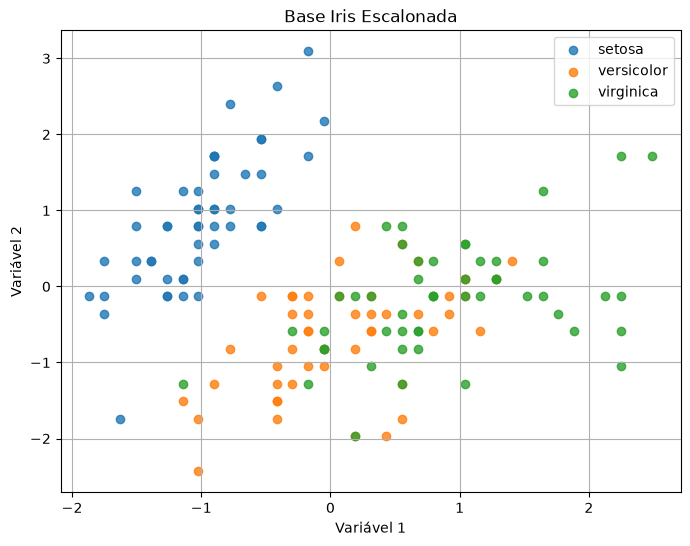

In [7]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

target_names = load_iris().target_names

plt.figure(figsize=(8, 6))

for class_id, class_name in enumerate(target_names):
    mask = y == class_id
    plt.scatter(
        X_scaled[mask, 0],
        X_scaled[mask, 1],
        label=class_name,
        alpha=0.8
    )

plt.xlabel("Variável 1")
plt.ylabel("Variável 2")
plt.title("Base Iris Escalonada")
plt.legend()
plt.grid(True)
plt.show()

### Dados após PCA

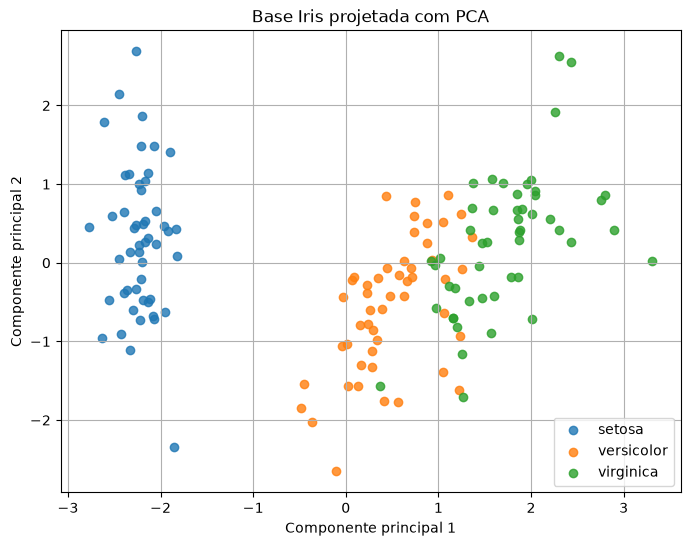

In [4]:
plt.figure(figsize=(8, 6))

for class_id, class_name in enumerate(target_names):
    mask = y == class_id
    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=class_name,
        alpha=0.8
    )

plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.title("Base Iris projetada com PCA")
plt.legend()
plt.grid(True)
plt.show()

## Analisando a variância explicada

O gráfico abaixo mostra a variância explicada por cada componente e a variância acumulada. Isso ajuda a avaliar quantos componentes seriam necessários para preservar determinada proporção da variabilidade dos dados.

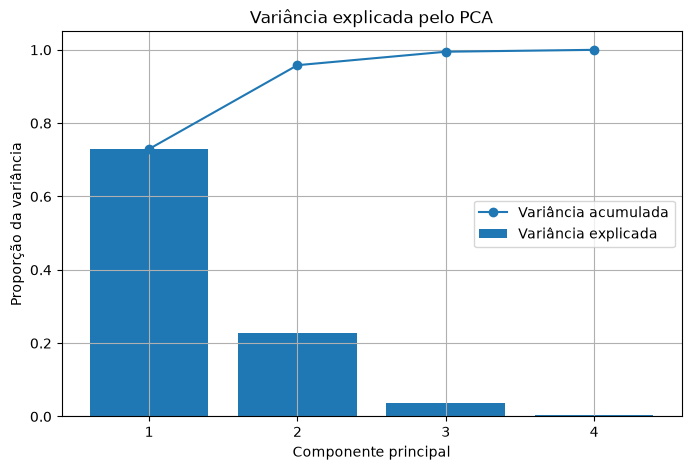

1 componente(s): 72.96% da variância acumulada
2 componente(s): 95.81% da variância acumulada
3 componente(s): 99.48% da variância acumulada
4 componente(s): 100.00% da variância acumulada


In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

pca_all = PCA()
pca_all.fit(X_scaled)

explained = pca_all.explained_variance_ratio_
cumulative = np.cumsum(explained)
components = np.arange(1, len(explained) + 1)

plt.figure(figsize=(8, 5))
plt.bar(components, explained, label="Variância explicada")
plt.plot(components, cumulative, marker="o", label="Variância acumulada")
plt.xticks(components)
plt.xlabel("Componente principal")
plt.ylabel("Proporção da variância")
plt.title("Variância explicada pelo PCA")
plt.legend()
plt.grid(True)
plt.show()

for n, value in enumerate(cumulative, start=1):
    print(f"{n} componente(s): {value:.2%} da variância acumulada")

## Selecionando componentes pela variância acumulada

Também é possível pedir ao PCA que selecione a quantidade de componentes necessária para explicar uma proporção da variância, como 95%. Para esse uso, `n_components` recebe um valor entre 0 e 1 e o solver precisa ser compatível; o solver padrão `auto` seleciona uma estratégia apropriada para esse caso.

In [6]:
pca_95 = PCA(n_components=0.95)
X_pca_95 = pca_95.fit_transform(X_scaled)

print(f"Quantidade original de características: {X_scaled.shape[1]}")
print(f"Quantidade de componentes selecionados: {pca_95.n_components_}")
print(f"Variância explicada acumulada: {pca_95.explained_variance_ratio_.sum():.2%}")
print("Formato após a transformação:", X_pca_95.shape)

Quantidade original de características: 4
Quantidade de componentes selecionados: 2
Variância explicada acumulada: 95.81%
Formato após a transformação: (150, 2)


### Resumo das funções utilizadas

| Função ou atributo | Finalidade |
|---|---|
| `StandardScaler` | Padroniza as características |
| `PCA(n_components=...)` | Define a quantidade de componentes ou a variância a preservar |
| `fit_transform(X)` | Aprende a transformação e transforma os dados |
| `transform(X)` | Aplica uma transformação já ajustada a novos dados |
| `explained_variance_ratio_` | Informa a proporção da variância explicada por componente |
| `n_components_` | Informa a quantidade de componentes selecionados após o ajuste |

O PCA permite representar dados com menos dimensões, explorar visualmente conjuntos de dados e, em alguns casos, reduzir o custo das etapas posteriores. A escolha da quantidade de componentes deve considerar a variância preservada, o objetivo da aplicação e o desempenho do modelo quando houver uma tarefa preditiva.